In [790]:
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')

file_path = '/content/drive/My Drive/Colab Notebooks/Data/car_details_v4.csv'

df = pd.read_csv(file_path)
df.head(2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0


In [791]:
df.shape

(2059, 20)

In [792]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

In [793]:
df.describe()

,Price,Year,Kilometer,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2.059000e+03,2059.000000,2.059000e+03,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
mean,1.702992e+06,2016.425449,5.422471e+04,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,2.419881e+06,3.363564,5.736172e+04,442.458507,135.265825,136.073956,0.822170,15.110198
min,4.900000e+04,1988.000000,0.000000e+00,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,4.849990e+05,2014.000000,2.900000e+04,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,8.250000e+05,2017.000000,5.000000e+04,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,1.925000e+06,2019.000000,7.200000e+04,4629.000000,1831.500000,1675.000000,5.000000,60.000000
max,3.500000e+07,2022.000000,2.000000e+06,5569.000000,2220.000000,1995.000000,8.000000,105.000000


Duplicate check - No duplicates

In [794]:
df.duplicated().sum()

np.int64(0)

**Missing value check**

Checking numerical column missing values

In [795]:
df.select_dtypes('number').isna().sum()

,0
Price,0
Year,0
Kilometer,0
Length,64
Width,64
Height,64
Seating Capacity,64
Fuel Tank Capacity,113


In [796]:
# Filling numerical values with median
df['Length'] = df['Length'].fillna(df['Length'].median())
df['Width'] = df['Width'].fillna(df['Width'].median())
df['Height'] = df['Height'].fillna(df['Height'].median())
df['Seating Capacity'] = df['Seating Capacity'].fillna(df['Seating Capacity'].median())
df['Fuel Tank Capacity'] = df['Fuel Tank Capacity'].fillna(df['Fuel Tank Capacity'].median())

In [797]:
df.select_dtypes('number').isna().sum()

,0
Price,0
Year,0
Kilometer,0
Length,0
Width,0
Height,0
Seating Capacity,0
Fuel Tank Capacity,0


Checking categorical column missing values

In [798]:
df.select_dtypes('object').isna().sum()

,0
Make,0
Model,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0
Seller Type,0
Engine,80
Max Power,80


Filling categorical column missing values with mode

In [799]:
df['Engine'] = df['Engine'].fillna(df['Engine'].mode()[0])
df['Max Power'] = df['Max Power'].fillna(df['Max Power'].mode()[0])
df['Max Torque'] = df['Max Torque'].fillna(df['Max Torque'].mode()[0])
df['Drivetrain'] = df['Drivetrain'].fillna(df['Drivetrain'].mode()[0])

In [800]:
df.select_dtypes('object').isna().sum()

,0
Make,0
Model,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0
Seller Type,0
Engine,0
Max Power,0


Drawing box plot and kde plot to check the skewness and outliers

**Box Plot**

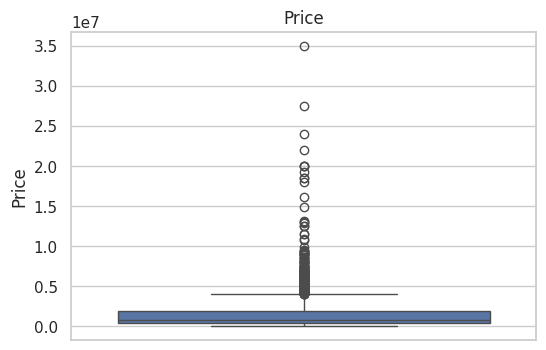

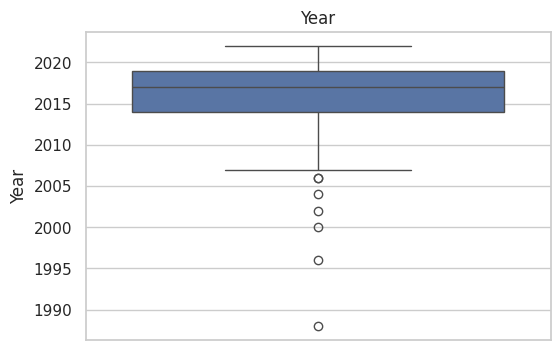

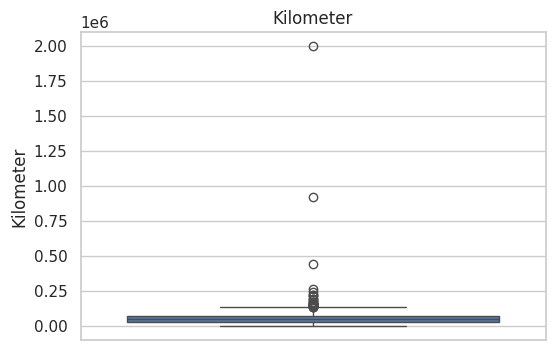

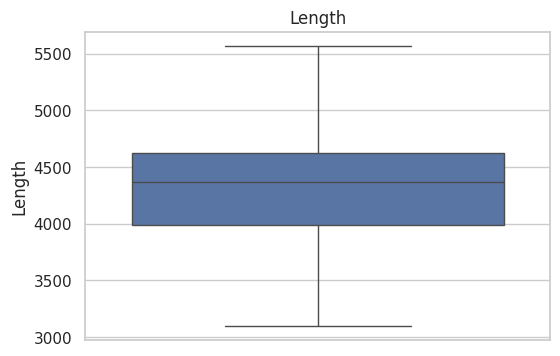

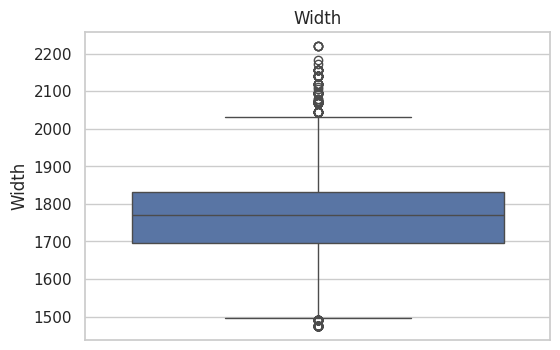

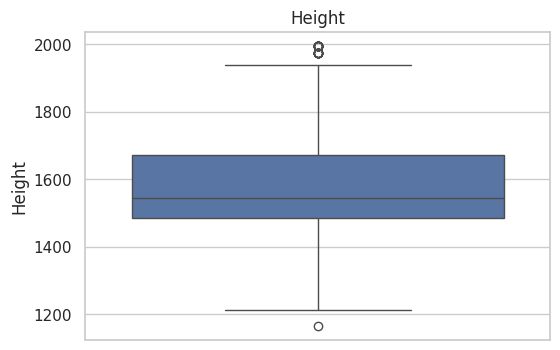

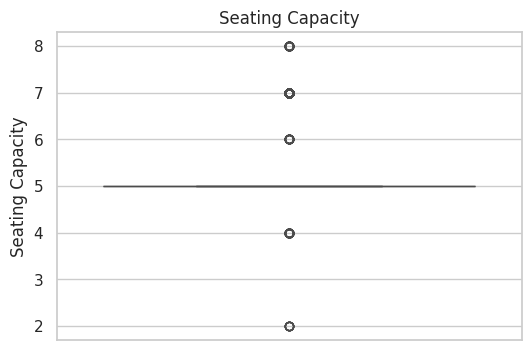

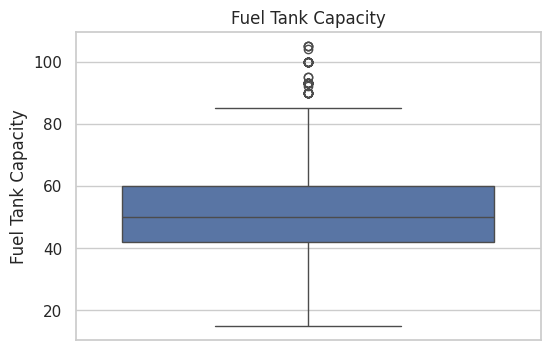

In [801]:
import matplotlib.pyplot as plt
import seaborn as sns
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(df[col])
    plt.title(col)
    plt.show()

According to box plot Price showing significant outlier. We are planning to use linear regression so checking whether this extreme values are genuine or a mistake

In [802]:
np.sort(df["Price"].unique())[::-1]

array([35000000, 27500000, 24000000, 22000000, 20000000, 19300000,
       18500000, 18000000, 16200000, 14900000, 13100000, 13000000,
       12900000, 12500000, 11500000, 10900000, 10800000,  9900000,
        9500000,  9400000,  9390000,  9300000,  9200000,  9100000,
        9000000,  8900000,  8600000,  8500000,  8300000,  8190000,
        8100000,  8000000,  7998999,  7990000,  7900000,  7780000,
        7700000,  7500000,  7475000,  7390000,  7350000,  7200000,
        7100000,  7050000,  7000000,  6975000,  6900000,  6875000,
        6800000,  6750000,  6700000,  6680000,  6600000,  6500000,
        6400000,  6390000,  6350000,  6300000,  6225000,  6200000,
        6150000,  6100000,  6000000,  5995000,  5975000,  5950000,
        5900000,  5850000,  5811000,  5800000,  5775000,  5651000,
        5600000,  5590000,  5500000,  5400000,  5375000,  5350000,
        5300000,  5250000,  5200000,  5175000,  5100000,  5000000,
        4975000,  4950000,  4900000,  4800000,  4775000,  4749

Checking price higher than 2 cr



In [803]:
print(df[df["Price"] > 20000000])

             Make                                Model     Price  Year  \
483       Ferrari                              488 GTB  35000000  2018   
510   Lamborghini                     Huracan LP 610-4  24000000  2016   
582    Land Rover      Range Rover 3.0 V6 Diesel Vogue  22000000  2019   
1305   Land Rover  Range Rover 3.0 V6 Diesel Vogue LWB  27500000  2020   

      Kilometer Fuel Type Transmission   Location  Color   Owner Seller Type  \
483        9500    Petrol    Automatic      Delhi  Black   First  Individual   
510        6000    Petrol    Automatic      Delhi   Blue   First  Individual   
582       35000    Diesel    Automatic       Pune   Blue   First  Individual   
1305      11000    Diesel    Automatic  Hyderabad  White  Second  Individual   

       Engine           Max Power         Max Torque Drivetrain  Length  \
483   3902 cc  660 bhp @ 8000 rpm  760 Nm @ 3000 rpm        RWD  4568.0   
510   5204 cc  602 bhp @ 8250 rpm  560 Nm @ 6500 rpm        AWD  4459.0   
582

Look like outlier values are genuine

**KDE Plot**

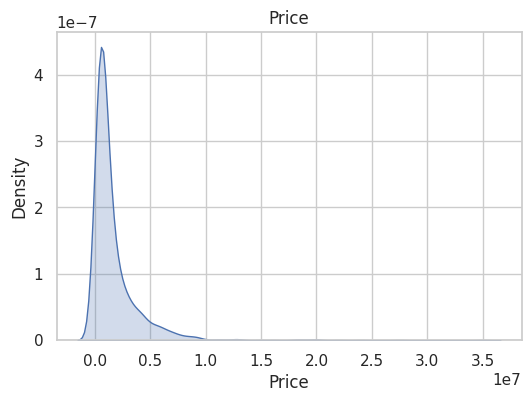

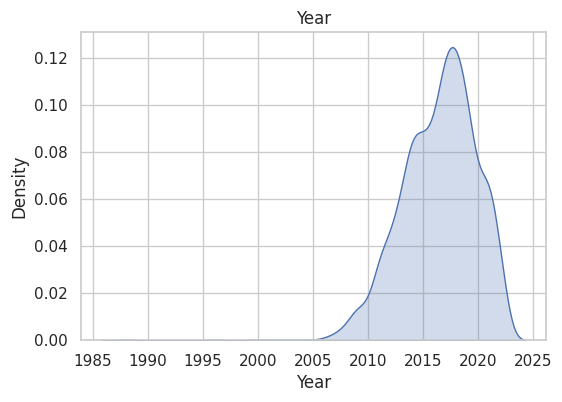

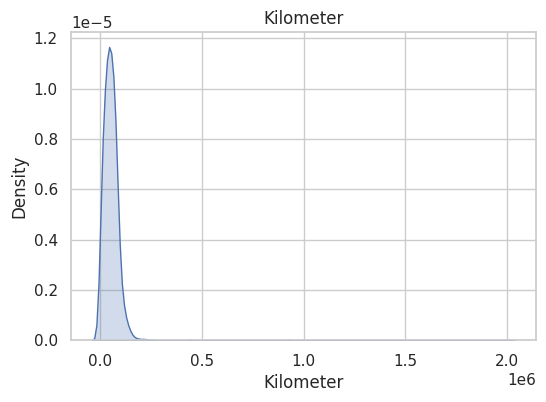

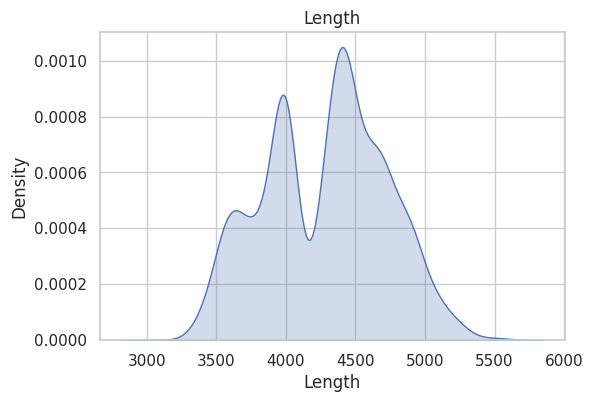

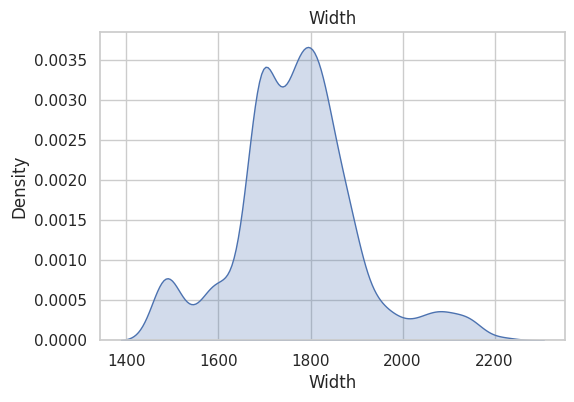

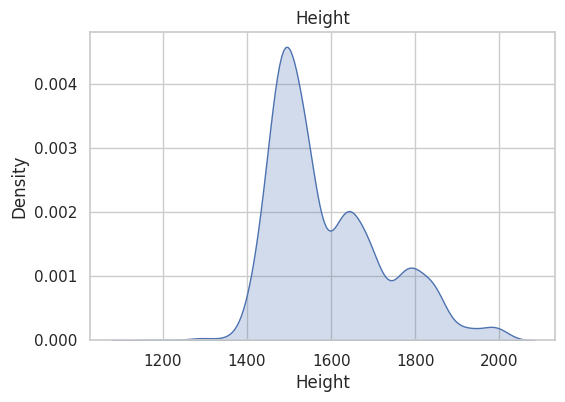

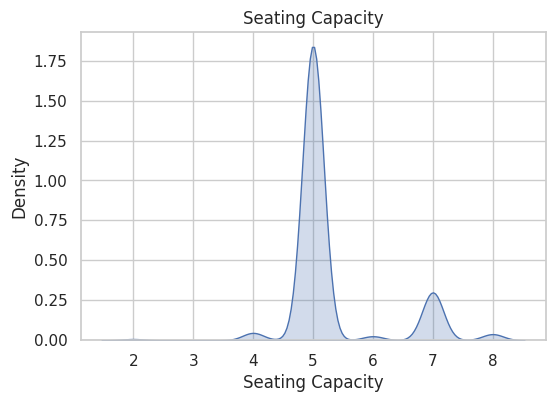

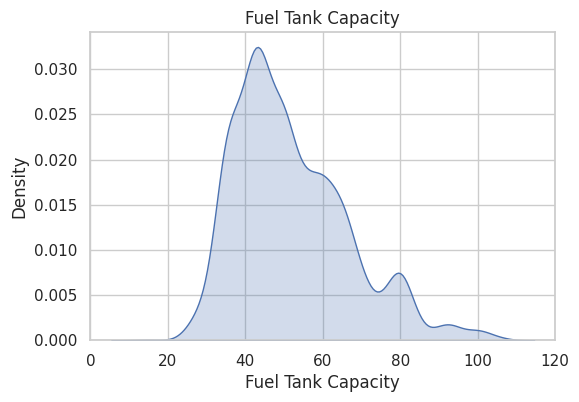

In [804]:
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.kdeplot(df[col], fill=True)
    plt.title(col)
    plt.show()


In [805]:
df.select_dtypes(include="number").skew().sort_values(ascending=False)

,0
Kilometer,20.980719
Price,4.965143
Seating Capacity,1.515381
Fuel Tank Capacity,0.898429
Height,0.877625
Width,0.311823
Length,-0.040649
Year,-0.840685


# **Feature Engineering**

Converting Year to age

In [806]:
# Numerical value year have no quantitative significance to target, so changing it to age
current_year = pd.Timestamp.now().year
df['Age'] = current_year - df['Year']
df.drop(["Year"], axis=1, inplace=True)

Checking Skewness

In [807]:
df.select_dtypes(include="number").skew().sort_values(ascending=False)

,0
Kilometer,20.980719
Price,4.965143
Seating Capacity,1.515381
Fuel Tank Capacity,0.898429
Height,0.877625
Age,0.840685
Width,0.311823
Length,-0.040649


Applying transformations for reducing skewness - Checking possible transformations of a feature and choosing which is closer to value 0

In [808]:
import numpy as np
from scipy.stats import boxcox
#Kilometer
df['Kilometer_Log'] = np.log1p(df['Kilometer'])
df['Kilometer_Reciprocal'] = 1 / (df['Kilometer'] + 1e-9)
df['Kilometer_BoxCox'], _ = boxcox(df['Kilometer'] + 1e-9)
print(f"LOG: {df['Kilometer_Log'].skew()}")
print(f"Reciprocal: {df['Kilometer_Reciprocal'].skew()}")
print(f"BoxCox: {df['Kilometer_BoxCox'].skew()}")
print(f"Kilometer: {df['Kilometer'].skew()}")

LOG: -3.0307422541592435
Reciprocal: 45.37620521815371
BoxCox: 0.31392109344429564
Kilometer: 20.980719033251866


In [809]:
df.drop(["Kilometer_Reciprocal","Kilometer_Log","Kilometer"], axis=1, inplace=True)

In [810]:
#Seating Capacity
df['Seating_Capacity_Sqrt'] = np.sqrt(df['Seating Capacity'])
df['Seating_Capacity_Log'] = np.log1p(df['Seating Capacity'])
df['Seating_Capacity_CubeRoot'] = np.cbrt(df['Seating Capacity'])
print(f"SQRT: {df['Seating_Capacity_Sqrt'].skew()}")
print(f"LOG: {df['Seating_Capacity_Log'].skew()}")
print(f"Cube Root: {df['Seating_Capacity_CubeRoot'].skew()}")
print(f"Seating Capacity: {df['Seating Capacity'].skew()}")

SQRT: 1.0950574786988456
LOG: 0.6828490807214771
Cube Root: 0.8907459095165008
Seating Capacity: 1.515380811893055


In [811]:
df.drop(["Seating_Capacity_Sqrt","Seating_Capacity_CubeRoot","Seating Capacity"], axis=1, inplace=True)

In [812]:
#Age
df['Age_BoxCox'], _ = boxcox(df['Age'] + 1e-9)
df['Age_CubeRoot'] = np.cbrt(df['Age'])
print(f"BoxCox: {df['Age_BoxCox'].skew()}")
print(f"CubeRoot: {df['Age_CubeRoot'].skew()}")
print(f"Age: {df['Age'].skew()}")

BoxCox: -0.008200472287189769
CubeRoot: 0.029544403959389624
Age: 0.8406845273317992


In [813]:
df.drop(["Age_CubeRoot","Age"], axis=1, inplace=True)

In [814]:
df.select_dtypes(include="number").skew().sort_values(ascending=False)

,0
Price,4.965143
Fuel Tank Capacity,0.898429
Height,0.877625
Seating_Capacity_Log,0.682849
Kilometer_BoxCox,0.313921
Width,0.311823
Age_BoxCox,-0.008200
Length,-0.040649


**Encoding**

Checking number of unique values and avoiding one hot encoding for the unique values more than 3 to avoid high dimensionality

In [815]:
df.select_dtypes(include="object").nunique()

,0
Make,33
Model,1050
Fuel Type,9
Transmission,2
Location,77
Color,17
Owner,6
Seller Type,3
Engine,108
Max Power,335


One Hot Encoding - Transmission, Seller Type, Drivetrain

Target Encoding - Make, Model, Fuel Type, Location, Color, Owner, Engine, Max Power, Max Torque

**One hot encoding**

In [816]:

enc_df=pd.get_dummies(df[['Transmission','Seller Type','Drivetrain']],drop_first=True,dtype=int)
df = pd.concat([df, enc_df], axis=1)
df.drop('Transmission', axis=1, inplace=True)
df.drop('Seller Type', axis=1, inplace=True)
df.drop('Drivetrain', axis=1, inplace=True)
df.columns


Index(['Make', 'Model', 'Price', 'Fuel Type', 'Location', 'Color', 'Owner',
       'Engine', 'Max Power', 'Max Torque', 'Length', 'Width', 'Height',
       'Fuel Tank Capacity', 'Kilometer_BoxCox', 'Seating_Capacity_Log',
       'Age_BoxCox', 'Transmission_Manual', 'Seller Type_Corporate',
       'Seller Type_Individual', 'Drivetrain_FWD', 'Drivetrain_RWD'],
      dtype='object')

**Target Encoding**

In [817]:

#Make
Make_mean = df.groupby('Make')['Price'].mean()
df['target_enc_Make'] = df['Make'].map(Make_mean)
df.drop('Make', axis=1, inplace=True)

#Model
Model_mean = df.groupby('Model')['Price'].mean()
df['target_enc_Model'] = df['Model'].map(Model_mean)
df.drop('Model', axis=1, inplace=True)

Fuel_Type_mean = df.groupby('Fuel Type')['Price'].mean()
df['target_enc_Fuel_Type'] = df['Fuel Type'].map(Fuel_Type_mean)
df.drop('Fuel Type', axis=1, inplace=True)

Location_mean = df.groupby('Location')['Price'].mean()
df['target_enc_Location'] = df['Location'].map(Location_mean)
df.drop('Location', axis=1, inplace=True)

Color_mean = df.groupby('Color')['Price'].mean()
df['target_enc_Color'] = df['Color'].map(Color_mean)
df.drop('Color', axis=1, inplace=True)

Owner_mean = df.groupby('Owner')['Price'].mean()
df['target_enc_Owner'] = df['Owner'].map(Owner_mean)
df.drop('Owner', axis=1, inplace=True)

Engine_mean = df.groupby('Engine')['Price'].mean()
df['target_enc_Engine'] = df['Engine'].map(Engine_mean)
df.drop('Engine', axis=1, inplace=True)

Max_Power_mean = df.groupby('Max Power')['Price'].mean()
df['target_enc_Max_Power'] = df['Max Power'].map(Max_Power_mean)
df.drop('Max Power', axis=1, inplace=True)

Max_Torque_mean = df.groupby('Max Torque')['Price'].mean()
df['target_enc_Max_Torque'] = df['Max Torque'].map(Max_Torque_mean)
df.drop('Max Torque', axis=1, inplace=True)

In [818]:
df

,Price,Length,Width,Height,Fuel Tank Capacity,Kilometer_BoxCox,Seating_Capacity_Log,Age_BoxCox,Transmission_Manual,Seller Type_Corporate,...,Drivetrain_RWD,target_enc_Make,target_enc_Model,target_enc_Fuel_Type,target_enc_Location,target_enc_Color,target_enc_Owner,target_enc_Engine,target_enc_Max_Power,target_enc_Max_Torque
0,505000,3990.0,1680.0,1505.0,35.0,142.661724,1.791759,3.090379,1,1,...,0,6.221076e+05,5.050000e+05,1.322041e+06,1.977764e+06,1.201441e+06,1.714159e+06,4.690732e+05,4.922608e+05,4.230000e+05
1,450000,3995.0,1695.0,1555.0,42.0,135.333139,1.791759,3.663977,1,0,...,0,5.348000e+05,4.147142e+05,2.101848e+06,1.475745e+06,1.775398e+06,1.438051e+06,6.253688e+05,5.276999e+05,5.340000e+05
2,220000,3585.0,1595.0,1550.0,35.0,130.071235,1.791759,4.143611,1,0,...,0,7.232635e+05,2.931250e+05,1.322041e+06,9.643333e+05,1.243000e+06,1.714159e+06,7.556945e+05,3.485500e+05,3.150000e+05
3,799000,3995.0,1745.0,1510.0,37.0,106.002563,1.791759,2.627576,1,0,...,0,1.729545e+06,7.622500e+05,1.322041e+06,7.424000e+05,1.330753e+06,1.714159e+06,7.556945e+05,6.688387e+05,7.101200e+05
4,1950000,4735.0,1830.0,1795.0,55.0,131.423771,2.079442,2.869208,1,0,...,1,1.729545e+06,1.927200e+06,2.101848e+06,1.721570e+06,1.201441e+06,1.714159e+06,2.196143e+06,2.196143e+06,1.842607e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2054,850000,4585.0,1890.0,1785.0,70.0,144.450888,2.079442,3.294833,1,0,...,0,1.083479e+06,8.500000e+05,2.101848e+06,2.980400e+06,1.775398e+06,1.714159e+06,1.286356e+06,1.074412e+06,1.033333e+06
2055,275000,3495.0,1550.0,1500.0,32.0,140.238592,1.791759,3.663977,1,0,...,0,7.232635e+05,2.625000e+05,1.322041e+06,1.507257e+06,1.775398e+06,1.438051e+06,2.611538e+05,2.745455e+05,2.745455e+05
2056,240000,3795.0,1680.0,1427.0,45.0,134.053587,1.791759,3.832409,1,0,...,0,1.474625e+06,2.400000e+05,1.322041e+06,1.149000e+06,9.630350e+05,1.714159e+06,4.526922e+05,2.550000e+05,2.550000e+05
2057,4290000,4936.0,1868.0,1479.0,65.0,125.464441,1.791759,2.869208,0,0,...,1,3.768967e+06,4.337900e+06,2.101848e+06,1.385207e+06,1.775398e+06,1.714159e+06,3.010732e+06,3.371000e+06,3.481778e+06


In [819]:
df.columns

Index(['Price', 'Length', 'Width', 'Height', 'Fuel Tank Capacity',
       'Kilometer_BoxCox', 'Seating_Capacity_Log', 'Age_BoxCox',
       'Transmission_Manual', 'Seller Type_Corporate',
       'Seller Type_Individual', 'Drivetrain_FWD', 'Drivetrain_RWD',
       'target_enc_Make', 'target_enc_Model', 'target_enc_Fuel_Type',
       'target_enc_Location', 'target_enc_Color', 'target_enc_Owner',
       'target_enc_Engine', 'target_enc_Max_Power', 'target_enc_Max_Torque'],
      dtype='object')

# **Scaling**

Choosing columns for scaling

In [820]:

numerical_cols = ['Kilometer_BoxCox','Seating_Capacity_Log','Fuel Tank Capacity','Height','Width','Length','Age_BoxCox']
numerical_cols

['Kilometer_BoxCox',
 'Seating_Capacity_Log',
 'Fuel Tank Capacity',
 'Height',
 'Width',
 'Length',
 'Age_BoxCox']

In [821]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])
print(df)

        Price    Length     Width    Height  Fuel Tank Capacity  \
0      505000 -0.673941 -0.661496 -0.635706           -1.149684   
1      450000 -0.662465 -0.548810 -0.263001           -0.673267   
2      220000 -1.603494 -1.300046 -0.300271           -1.149684   
3      799000 -0.662465 -0.173193 -0.598435           -1.013565   
4     1950000  1.035978  0.465357  1.525984            0.211507   
...       ...       ...       ...       ...                 ...   
2054   850000  0.691699  0.916099  1.451443            1.232400   
2055   275000 -1.810061 -1.638102 -0.672976           -1.353862   
2056   240000 -1.121503 -0.661496 -1.217126           -0.469089   
2057  4290000  1.497312  0.750827 -0.829513            0.892102   
2058   670000 -0.662465 -0.173193  2.159583           -0.128791   

      Kilometer_BoxCox  Seating_Capacity_Log  Age_BoxCox  Transmission_Manual  \
0             0.976066             -0.335659   -0.051239                    1   
1             0.727433           

In [822]:
x = df[['Length', 'Width', 'Height', 'Fuel Tank Capacity',
       'Kilometer_BoxCox', 'Seating_Capacity_Log', 'Age_BoxCox',
       'Transmission_Manual', 'Seller Type_Corporate',
       'Seller Type_Individual', 'Drivetrain_FWD', 'Drivetrain_RWD',
       'target_enc_Make', 'target_enc_Model', 'target_enc_Fuel_Type',
       'target_enc_Location', 'target_enc_Color', 'target_enc_Owner',
       'target_enc_Engine', 'target_enc_Max_Power', 'target_enc_Max_Torque']]
y = df["Price"]

x.shape, y.shape

((2059, 21), (2059,))

In [823]:
x

,Length,Width,Height,Fuel Tank Capacity,Kilometer_BoxCox,Seating_Capacity_Log,Age_BoxCox,Transmission_Manual,Seller Type_Corporate,Seller Type_Individual,...,Drivetrain_RWD,target_enc_Make,target_enc_Model,target_enc_Fuel_Type,target_enc_Location,target_enc_Color,target_enc_Owner,target_enc_Engine,target_enc_Max_Power,target_enc_Max_Torque
0,-0.673941,-0.661496,-0.635706,-1.149684,0.976066,-0.335659,-0.051239,1,1,0,...,0,6.221076e+05,5.050000e+05,1.322041e+06,1.977764e+06,1.201441e+06,1.714159e+06,4.690732e+05,4.922608e+05,4.230000e+05
1,-0.662465,-0.548810,-0.263001,-0.673267,0.727433,-0.335659,0.789001,1,0,1,...,0,5.348000e+05,4.147142e+05,2.101848e+06,1.475745e+06,1.775398e+06,1.438051e+06,6.253688e+05,5.276999e+05,5.340000e+05
2,-1.603494,-1.300046,-0.300271,-1.149684,0.548915,-0.335659,1.491598,1,0,1,...,0,7.232635e+05,2.931250e+05,1.322041e+06,9.643333e+05,1.243000e+06,1.714159e+06,7.556945e+05,3.485500e+05,3.150000e+05
3,-0.662465,-0.173193,-0.598435,-1.013565,-0.267649,-0.335659,-0.729180,1,0,1,...,0,1.729545e+06,7.622500e+05,1.322041e+06,7.424000e+05,1.330753e+06,1.714159e+06,7.556945e+05,6.688387e+05,7.101200e+05
4,1.035978,0.465357,1.525984,0.211507,0.594802,2.037941,-0.375223,1,0,1,...,1,1.729545e+06,1.927200e+06,2.101848e+06,1.721570e+06,1.201441e+06,1.714159e+06,2.196143e+06,2.196143e+06,1.842607e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2054,0.691699,0.916099,1.451443,1.232400,1.036766,2.037941,0.248257,1,0,1,...,0,1.083479e+06,8.500000e+05,2.101848e+06,2.980400e+06,1.775398e+06,1.714159e+06,1.286356e+06,1.074412e+06,1.033333e+06
2055,-1.810061,-1.638102,-0.672976,-1.353862,0.893857,-0.335659,0.789001,1,0,1,...,0,7.232635e+05,2.625000e+05,1.322041e+06,1.507257e+06,1.775398e+06,1.438051e+06,2.611538e+05,2.745455e+05,2.745455e+05
2056,-1.121503,-0.661496,-1.217126,-0.469089,0.684022,-0.335659,1.035730,1,0,1,...,0,1.474625e+06,2.400000e+05,1.322041e+06,1.149000e+06,9.630350e+05,1.714159e+06,4.526922e+05,2.550000e+05,2.550000e+05
2057,1.497312,0.750827,-0.829513,0.892102,0.392623,-0.335659,-0.375223,0,0,1,...,1,3.768967e+06,4.337900e+06,2.101848e+06,1.385207e+06,1.775398e+06,1.714159e+06,3.010732e+06,3.371000e+06,3.481778e+06


In [824]:
y

,Price
0,505000
1,450000
2,220000
3,799000
4,1950000
...,...
2054,850000
2055,275000
2056,240000
2057,4290000


In [825]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test =train_test_split(x,y,test_size=.2,random_state=42)

In [826]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((1647, 21), (1647,), (412, 21), (412,))

In [827]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(x_train, y_train)


LinearRegression()

In [828]:
y_pred = model1.predict(x_test)

In [829]:
results = pd.DataFrame({
    "Actual ": y_test.values,
    "Predicted ": y_pred.astype(int)
})
results

,Actual,Predicted
0,4800000,4706105
1,825000,798905
2,695000,661976
3,950000,793170
4,819999,788873
...,...,...
407,275000,198392
408,1550000,2493513
409,5590000,5990734
410,325000,327101


In [830]:
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error
import numpy as np
# Regression metrics
r2 = r2_score(y_test, y_pred)*100
mae = mean_absolute_error(y_test, y_pred)
mse=mean_squared_error(y_test, y_pred)

print(f"\nR² Score: {r2:.4f}")
print(f"Mean Absolute Error: {int(mae):,}")
print(f"Mean Squared Error: {int(mse):,}")
print(f"Root Mean Squared Error: {int(np.sqrt(mse))}")


R² Score: 97.4054
Mean Absolute Error: 170,844
Mean Squared Error: 181,263,330,365
Root Mean Squared Error: 425750


In [831]:
np.average(df["Price"])

np.float64(1702991.6964545897)

In [832]:
y_test_pred = model1.predict(x_test)
y_train_pred = model1.predict(x_train)

test_r2 = r2_score(y_test, y_test_pred) * 100
train_r2 = r2_score(y_train, y_train_pred) * 100

print(f"Test R2 : {test_r2}")
print(f"Train R2 : {train_r2}")


Test R2 : 97.40543932441534
Train R2 : 98.31013179814501


Difference between test and train r2 score is lest than 1 percentage so it is optimal fit.

Mae 170,844 means on average prediction deviates from the actual price value by 170844 rupees.

RMSE 425750 means prediction values deviates from the actual value by 425750 rupees

Assumption: There is genuine outliers of more than 1 cr amount in price, which is quite a few compared to the the most of the values.


